<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS07/JS07_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS07 - Klasterisasi: Lab 3 (Klasterisasi pada Kompresi Citra)

Klasterisasi tidak hanya dapat digunakan pada data tabular. Pada konteks citra, klasterisasi dapat digunakan untuk mengidentifikasi kesamaan warna sehingga mendapatkan area tertentu, maupun untuk **kompresi warna citra** - meminimalkan penggunaan rentang warna untuk mendapatkan citra dengan ukuran data yang lebih rendah.


## Langkah 0 - Import Library

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Langkah 1 - Load Data Citra

Gunakan 1 data citra dari dataset bawaan scikit-learn (`flower.jpg`).

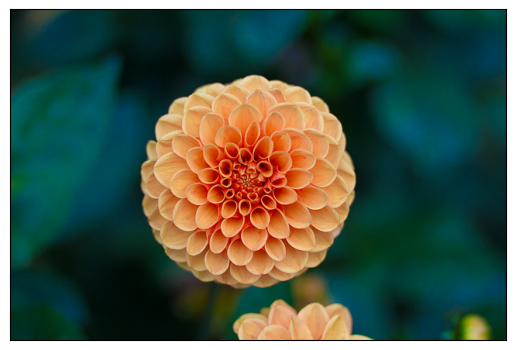

In [2]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)

## Langkah 2 - Preprocessing

Cek ukuran citra dan normalisasi warna ke rentang 0-1.

In [3]:
# Check shape
print(flower.shape)

# Normalize color
data = flower / 255.0

# Reshape
data = data.reshape(427 * 640, 3)  # turn to 1D

print(data.shape)

(427, 640, 3)
(273280, 3)


## Langkah 3 - Cek Sebaran Warna

In [4]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

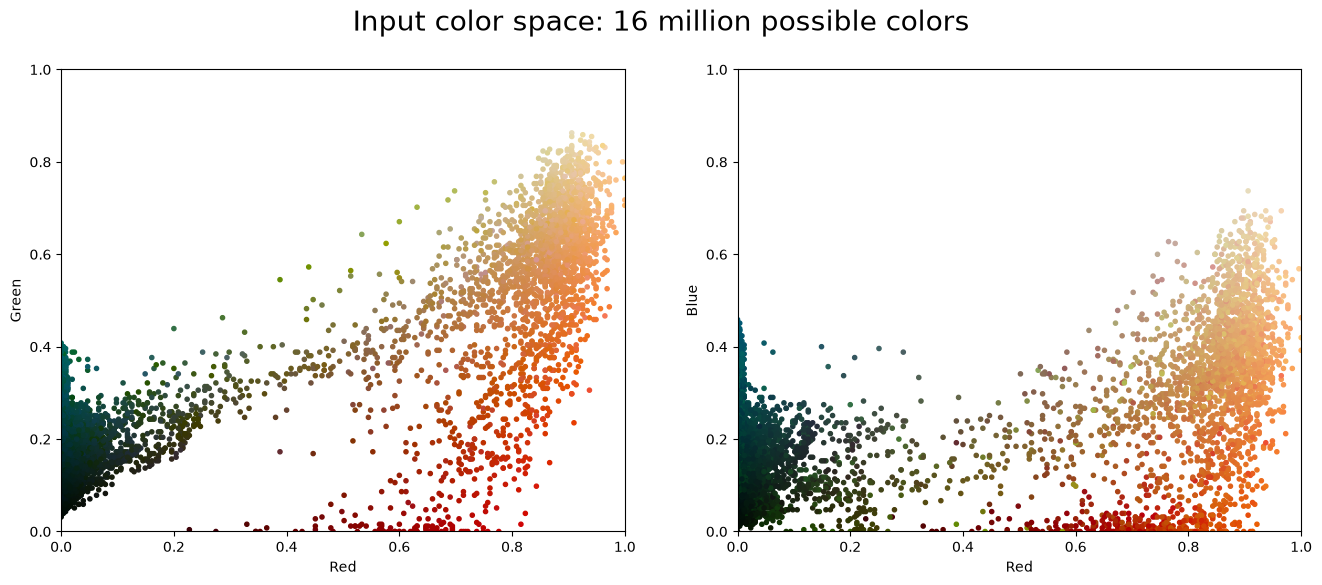

In [5]:
plot_pixels(data, title='Input color space: 16 million possible colors')

## Langkah 4 - Klasterisasi Warna

Klasterisasi hanya dengan **16 warna** saja menggunakan `MiniBatchKMeans` (varian K-Means yang memproses data dalam batch kecil sehingga lebih cepat untuk data besar).

> **Catatan:** `random_state=0` ditambahkan agar hasil kompresi dapat direproduksi.

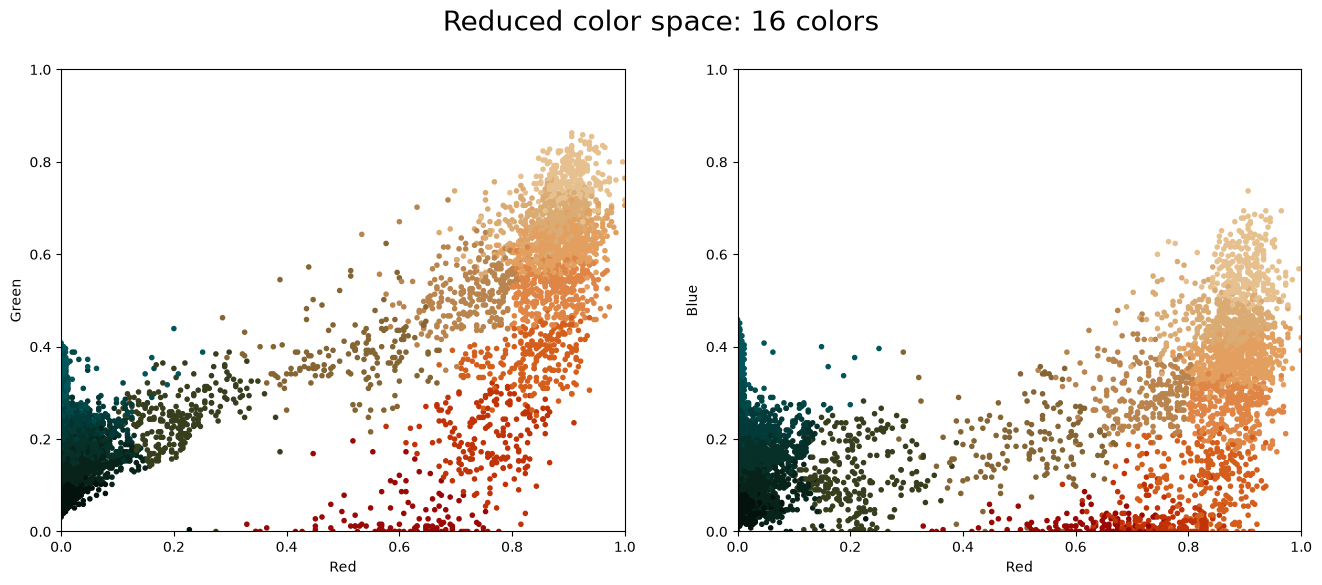

In [6]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16, random_state=0, n_init=3)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors, title="Reduced color space: 16 colors")

Hasil perbandingan warna citra sebelum dan setelah kompresi:

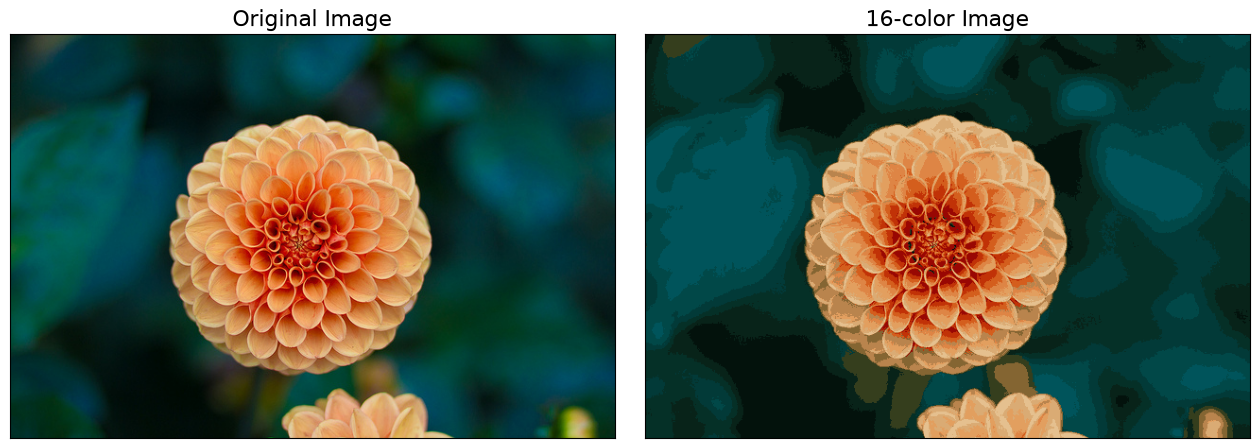

In [7]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

In [8]:
# Perbandingan jumlah warna unik dan estimasi kebutuhan bit
n_unique_orig = len(np.unique(flower.reshape(-1, 3), axis=0))
n_unique_new = len(np.unique(flower_recolored.reshape(-1, 3).astype(np.uint8), axis=0))
print(f'Jumlah warna unik sebelum : {n_unique_orig}')
print(f'Jumlah warna unik sesudah : {n_unique_new} (16 cluster warna)')
print(f'Setiap piksel awalnya butuh 24 bit (RGB 8 bit/kanal),')
print(f'setelah kompresi cukup 4 bit/piksel (indeks ke 16 warna) -> ~6x lebih hemat')

Jumlah warna unik sebelum : 62941
Jumlah warna unik sesudah : 1 (16 cluster warna)
Setiap piksel awalnya butuh 24 bit (RGB 8 bit/kanal),
setelah kompresi cukup 4 bit/piksel (indeks ke 16 warna) -> ~6x lebih hemat


**Kesimpulan Lab 3:** Kualitas citra setelah kompresi masih terlihat baik (detil utama tetap terjaga) meskipun warna yang digunakan hanya 16 cluster. Inilah kontribusi klasterisasi pada kompresi warna citra: merepresentasikan jutaan kemungkinan warna dengan sejumlah kecil warna representatif (centroid) tanpa mengorbankan keterbacaan visual.